# 02. 실험 결과 정리 (validation)

`scripts/run_experiment.py`가 만든 `results/metrics/e*.csv`를 읽어 요약 표·그림을 만들고, 기본 TrustRank의 오류를 들여다본다.

- 모든 숫자는 **validation**이다. test는 `run_final_test.py`에서 마지막에 한 번만 본다.
- 실행 순서: 위에서부터 Run All. 1·2절은 CSV만, 3절은 `data/processed/`가 필요하다.
- 출력: 요약 표 → `results/metrics/summary_e*.md`, 그림 → `results/figures/*.png`

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
METRICS = ROOT / "results" / "metrics"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

E = {name: pd.read_csv(METRICS / f"{name}.csv") for name in ["e1", "e2", "e3", "e4", "e5"]
     if (METRICS / f"{name}.csv").exists()}
for df in E.values():                                # seed_strategy 열이 생기기 전에 만든 CSV는 random
    if "seed_strategy" not in df:
        df["seed_strategy"] = "random"
PREVALENCE = E["e1"]["prevalence"].iloc[0]          # val spam 비율 = PR-AUC의 무작위 기준선
print({k: len(v) for k, v in E.items()}, f"val spam 비율 {PREVALENCE:.4f}")

# 그림 공통 설정 (dataviz reference palette, light). 방법 색은 고정: 같은 방법은 모든 그림에서 같은 색.
COLOR = {"trustrank": "#257de0", "spam_mass": "#f47230", "hop": "#00b894"}
LABEL = {"random": "Random", "indegree": "In-degree", "pagerank": "PageRank",
         "pagerank_weighted": "PageRank (weighted)", "inverse_pagerank": "Inverse PageRank",
         "ppr": "PPR (ac.uk·gov.uk seeds)", "trustrank": "TrustRank", "spam_mass": "Spam mass",
         "hop": "Hop distance"}
INK, INK2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight"})

{'e1': 50, 'e2': 40, 'e3': 120, 'e4': 40, 'e5': 40} val spam 비율 0.0558


## 1. 요약 표

조건(방법 × 설정)마다 random_seed 5번을 묶는다.

| 열 | 뜻 |
|---|---|
| PR-AUC | 5번 평균 ± 표준편차 |
| 95% CI | 5번 bootstrap CI의 평균 (대략적인 폭) |
| Δ vs ref | 기준 조건과의 PR-AUC 차이 (같은 random_seed끼리 paired, 5번 평균) |
| ↑ / ↓ | 차이 CI가 0보다 확실히 위 / 아래였던 횟수 (5번 중) |

In [2]:
def summarize(df, keys):
    df = df[df["eval_subset"] == "val"]
    g = df.groupby(keys, sort=False)
    out = pd.DataFrame({
        "PR-AUC": g["pr_auc"].mean(), "sd": g["pr_auc"].std().fillna(0),
        "CI lo": g["pr_auc_lo"].mean(), "CI hi": g["pr_auc_hi"].mean(),
        "ROC-AUC": g["roc_auc"].mean(), "P@100": g["p@100"].mean(), "tie": g["tie_frac"].mean(),
        "Δ vs ref": g["diff_vs_ref"].mean(),
        "↑": g["diff_lo"].apply(lambda s: int((s > 0).sum())),
        "↓": g["diff_hi"].apply(lambda s: int((s < 0).sum())),
        "runs": g.size()})
    return out


def md_table(t):
    """pandas.to_markdown은 tabulate가 필요해서 직접 만든다."""
    fmt = lambda v: (f"{v:.0f}" if float(v).is_integer() else f"{v:.4f}") if isinstance(v, float) else str(v)
    head = "| " + " | ".join(map(str, t.columns)) + " |"
    rule = "|" + "|".join("---" for _ in t.columns) + "|"
    body = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in t.itertuples(index=False)]
    return "\n".join([head, rule, *body])


def to_markdown(table, title, note):
    t = table.reset_index()
    t["PR-AUC"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(t["PR-AUC"], t["sd"])]
    t["95% CI"] = [f"{lo:.3f}–{hi:.3f}" for lo, hi in zip(t["CI lo"], t["CI hi"])]
    t["Δ vs ref"] = [("기준" if abs(d) < 1e-12 else f"{d:+.4f}") if pd.notna(d) else "" for d in t["Δ vs ref"]]
    if "method" in t:
        t["method"] = t["method"].map(LABEL).fillna(t["method"])
    t = t.drop(columns=["sd", "CI lo", "CI hi"])
    cols = [c for c in t.columns if c not in ("PR-AUC", "95% CI")]
    i = cols.index("ROC-AUC")
    cols = cols[:i] + ["PR-AUC", "95% CI"] + cols[i:]
    return f"### {title}\n\n{note}\n\n" + md_table(t[cols]) + "\n"


TABLES = {
    "e1": (["method"], "E1 방법 비교", "기준: 같은 random_seed의 기본 TrustRank (seed 100, noise 0, β 0.85)."),
    "e2": (["method", "seed_strategy"], "E2 seed 선정 전략", "seed 100개로 같게 두고 고르는 후보만 바꿈. 기준: random."),
    "e3": (["method", "n_seeds"], "E3 seed 개수", "기준: seed 100개."),
    "e4": (["method", "contamination_rate"], "E4 seed noise", "기준: noise 0."),
    "e5": (["method", "beta"], "E5 β", "기준: β 0.85."),
}
for name, (keys, title, note) in TABLES.items():
    if name not in E:
        print(f"{name}.csv 없음 → 건너뜀")
        continue
    table = summarize(E[name], keys)
    if name == "e1":
        table = table.sort_values("PR-AUC", ascending=False)
    text = to_markdown(table, title, note + f" val spam 비율(무작위 PR-AUC) = {PREVALENCE:.4f}.")
    (METRICS / f"summary_{name}.md").write_text(text, encoding="utf-8")
    display(table.round(4))

,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,,,,,,,,,,,
ppr,0.0913,0.0000,0.0734,0.1269,0.6605,0.0860,0.0392,0.0073,5,0,5
indegree,0.0857,0.0000,0.0690,0.1176,0.6335,0.1058,0.1067,0.0011,0,0,5
spam_mass,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
hop,0.0834,0.0055,0.0688,0.1132,0.6348,0.1095,0.5077,-0.0017,0,0,5
pagerank,0.0739,0.0000,0.0579,0.1059,0.5588,0.0800,0.0367,-0.0104,0,3,5
pagerank_weighted,0.0713,0.0000,0.0554,0.1024,0.5417,0.0900,0.0367,-0.0133,0,4,5
random,0.0645,0.0076,0.0494,0.1002,0.4988,0.0500,0.0008,-0.0196,0,1,5
inverse_pagerank,0.0642,0.0000,0.0531,0.0774,0.5295,0.0706,0.4133,-0.0228,0,3,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,seed_strategy,,,,,,,,,,,
trustrank,random,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
spam_mass,random,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,domain,0.0899,0.0011,0.0717,0.1260,0.6493,0.0904,0.0392,0.0059,2,0,5
spam_mass,domain,0.0921,0.0011,0.0741,0.1289,0.6636,0.0894,0.0392,0.0081,5,0,5
trustrank,commercial,0.0819,0.0039,0.0632,0.1180,0.5881,0.0940,0.0392,-0.0023,0,2,5
spam_mass,commercial,0.0825,0.0046,0.0637,0.1188,0.5895,0.0930,0.0392,-0.0016,1,2,5
trustrank,high_pr,0.0914,0.0000,0.0711,0.1325,0.6307,0.1110,0.0392,0.0077,4,0,5
spam_mass,high_pr,0.0932,0.0000,0.0728,0.1346,0.6383,0.1100,0.0392,0.0095,5,0,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,n_seeds,,,,,,,,,,,
trustrank,10,0.0856,0.0029,0.0673,0.1221,0.6226,0.0860,0.0392,0.0015,0,1,5
spam_mass,10,0.0872,0.0033,0.0690,0.1240,0.6307,0.0868,0.0392,0.0031,2,0,5
hop,10,0.0808,0.0039,0.0659,0.1112,0.6206,0.1064,0.4978,-0.0044,0,1,5
trustrank,20,0.0851,0.0021,0.0668,0.1216,0.6167,0.0864,0.0392,0.0010,0,1,5
spam_mass,20,0.0865,0.0024,0.0681,0.1230,0.6245,0.0854,0.0392,0.0024,1,0,5
hop,20,0.0793,0.0048,0.0643,0.1087,0.6126,0.1048,0.5217,-0.0060,0,1,5
trustrank,50,0.0834,0.0026,0.0651,0.1195,0.6067,0.0918,0.0392,-0.0007,0,1,5
spam_mass,50,0.0846,0.0030,0.0662,0.1208,0.6144,0.0908,0.0392,0.0005,1,0,5
hop,50,0.0852,0.0065,0.0699,0.1152,0.6424,0.1134,0.5368,0.0000,0,0,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,contamination_rate,,,,,,,,,,,
trustrank,0.00,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
spam_mass,0.00,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,0.05,0.0834,0.0030,0.0648,0.1196,0.6044,0.0908,0.0392,-0.0007,0,1,5
spam_mass,0.05,0.0845,0.0036,0.0660,0.1211,0.6122,0.0898,0.0392,0.0004,0,0,5
trustrank,0.10,0.0820,0.0023,0.0637,0.1178,0.5979,0.0892,0.0392,-0.0021,0,2,5
spam_mass,0.10,0.0831,0.0029,0.0648,0.1193,0.6051,0.0882,0.0392,-0.0010,0,1,5
trustrank,0.20,0.0819,0.0042,0.0633,0.1175,0.5921,0.0908,0.0392,-0.0023,0,3,5
spam_mass,0.20,0.0828,0.0050,0.0642,0.1190,0.5987,0.0900,0.0392,-0.0013,0,1,5


,,PR-AUC,sd,CI lo,CI hi,ROC-AUC,P@100,tie,Δ vs ref,↑,↓,runs
method,beta,,,,,,,,,,,
trustrank,0.70,0.0845,0.0029,0.0660,0.1211,0.6099,0.0938,0.0392,0.0004,0,0,5
spam_mass,0.70,0.0853,0.0031,0.0667,0.1218,0.6158,0.0932,0.0392,0.0012,0,0,5
trustrank,0.80,0.0843,0.0029,0.0656,0.1208,0.6089,0.0930,0.0392,0.0002,0,0,5
spam_mass,0.80,0.0854,0.0032,0.0669,0.1222,0.6166,0.0940,0.0392,0.0013,1,0,5
trustrank,0.85,0.0841,0.0029,0.0654,0.1205,0.6080,0.0920,0.0392,0.0000,0,0,5
spam_mass,0.85,0.0854,0.0034,0.0669,0.1221,0.6172,0.0910,0.0392,0.0014,2,0,5
trustrank,0.90,0.0839,0.0029,0.0652,0.1203,0.6074,0.0920,0.0392,-0.0002,0,0,5
spam_mass,0.90,0.0855,0.0036,0.0671,0.1220,0.6184,0.0906,0.0392,0.0015,2,0,5


In [3]:
# PPR: seed host(ac.uk·gov.uk)를 뺀 val로도 평가해 seed 효과를 확인한다.
ppr = E["e1"][E["e1"]["method"] == "ppr"].groupby("eval_subset")[["n_eval", "n_pos", "pr_auc", "roc_auc"]].mean()
ppr.round(4)

,n_eval,n_pos,pr_auc,roc_auc
eval_subset,,,,
val,1200.0,67.0,0.0913,0.6605
val_no_seed,1143.0,67.0,0.0913,0.6425


## 2. 그림

- E1 막대의 오차 막대는 95% bootstrap CI(5번 평균), 회색 점선은 무작위 기준선(val spam 비율)이다.
- E3–E5는 두 칸이다. 왼쪽은 조건별 PR-AUC(5번 평균), 오른쪽은 기준 조건과의 **paired 차이**와 95% CI다. 조건별 CI는 서로 크게 겹쳐서 비교에 쓰기 어렵고, 같은 bootstrap 표본으로 계산한 차이 CI가 0을 넘지 않으면 차이가 확실하다고 본다.
- 같은 방법은 모든 그림에서 같은 색이다 (TrustRank 파랑, Spam mass 주황, Hop 청록).

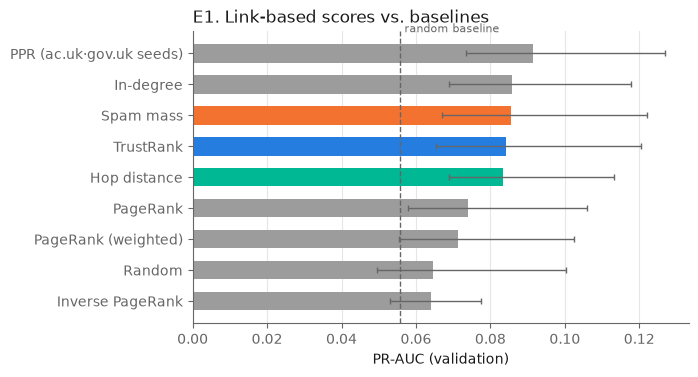

In [4]:
def ci_err(t):
    return np.vstack([t["PR-AUC"] - t["CI lo"], t["CI hi"] - t["PR-AUC"]])


# E1: 방법별 PR-AUC (가로 막대, 높은 순)
t1 = summarize(E["e1"], ["method"]).sort_values("PR-AUC")
fig, ax = plt.subplots(figsize=(6.4, 3.8))
colors = [COLOR.get(m, "#9c9c9c") for m in t1.index]
y = np.arange(len(t1))
ax.barh(y, t1["PR-AUC"], height=0.6, color=colors)
ax.errorbar(t1["PR-AUC"], y, xerr=ci_err(t1), fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
ax.axvline(PREVALENCE, color=INK2, linestyle="--", linewidth=1)
ax.text(PREVALENCE, len(t1) - 0.4, " random baseline", color=INK2, fontsize=8, va="bottom")
ax.set_yticks(y, [LABEL[m] for m in t1.index])
ax.set_xlabel("PR-AUC (validation)")
ax.set_title("E1. Link-based scores vs. baselines", loc="left", color=INK)
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "e1_methods.png")
plt.show()

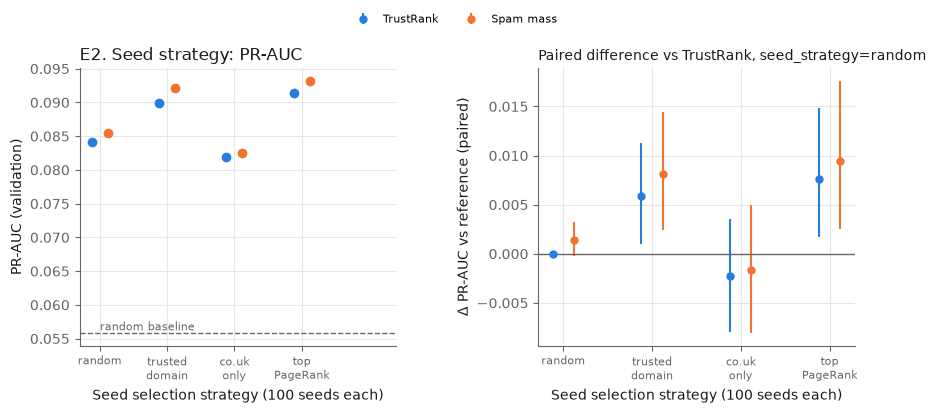

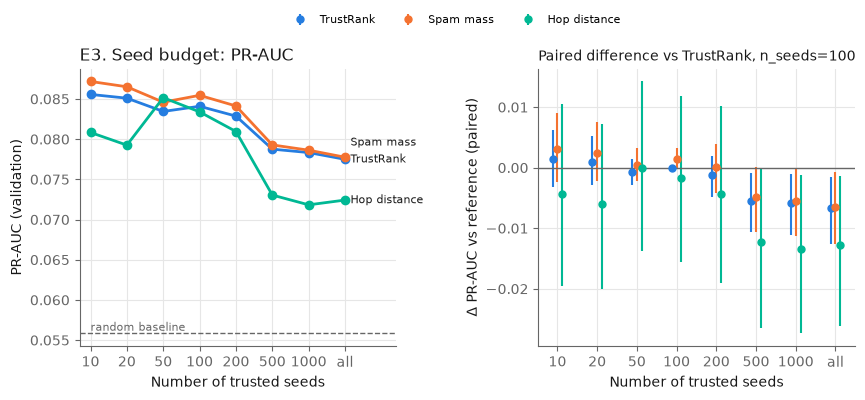

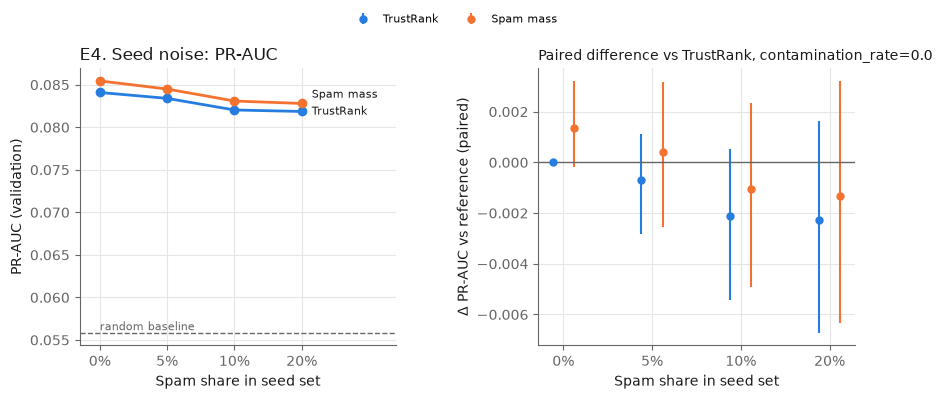

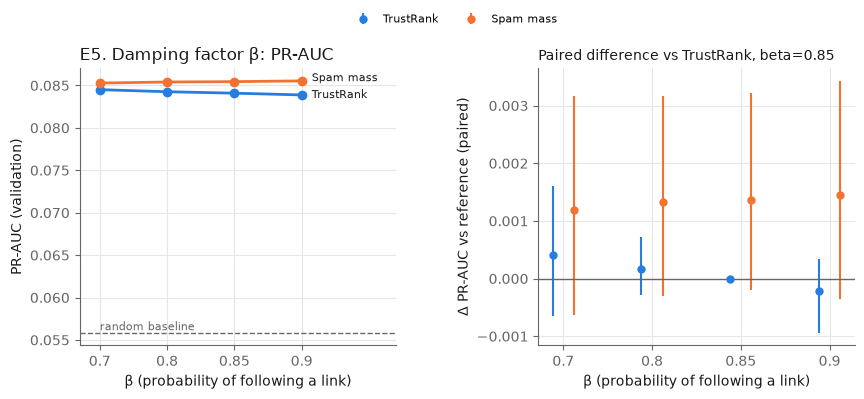

In [5]:
def label_ends(ax, x_end, ends, min_gap):
    """선 끝 직접 라벨이 겹치지 않게 위아래로 조금씩 민다."""
    items = sorted(ends.items(), key=lambda kv: kv[1])
    placed = []
    for method, yv in items:
        y_pos = max(yv, placed[-1] + min_gap) if placed else yv
        placed.append(y_pos)
        ax.annotate(LABEL[method], (x_end, yv), xytext=(x_end + 0.15, y_pos), textcoords="data",
                    color=INK, fontsize=8, va="center")


def sweep(name, key, xlabel, title, fname, xticks=None, categorical=False):
    """왼쪽: 조건별 PR-AUC (5번 평균). 오른쪽: 기준 조건과의 paired 차이와 95% CI."""
    t = summarize(E[name], ["method", key]).reset_index()
    order = list(dict.fromkeys(E[name][key]))           # 설정 파일 순서 그대로
    x = np.arange(len(order))
    ticks = xticks or [str(v) for v in order]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"wspace": 0.45})
    methods = list(dict.fromkeys(t["method"]))
    offsets = np.linspace(-0.12, 0.12, len(methods))

    ends = {}
    for method in methods:
        g = t[t["method"] == method].set_index(key).loc[order]
        ax1.plot(x + (offsets[methods.index(method)] if categorical else 0), g["PR-AUC"], color=COLOR[method],
                 linewidth=0 if categorical else 2, marker="o", markersize=6, label=LABEL[method])
        ends[method] = g["PR-AUC"].iloc[-1]
    ax1.axhline(PREVALENCE, color=INK2, linestyle="--", linewidth=1)
    ax1.text(x[0], PREVALENCE, "random baseline", color=INK2, fontsize=8, va="bottom")
    span = ax1.get_ylim()[1] - ax1.get_ylim()[0]
    if not categorical:                                 # 범주형(E2)은 점이 흩어져 있어 범례만 둔다
        label_ends(ax1, x[-1], ends, min_gap=span * 0.06)
    ax1.set_xlim(-0.3, len(order) - 1 + 1.4)
    ax1.set_xticks(x, ticks, fontsize=8 if categorical else None)
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel("PR-AUC (validation)")
    ax1.set_title(f"{title}: PR-AUC", loc="left", color=INK)

    for off, method in zip(offsets, methods):
        g = t[t["method"] == method].set_index(key).loc[order]
        lo = (E[name].query("eval_subset == 'val' and method == @method").groupby(key)["diff_lo"].mean().loc[order])
        hi = (E[name].query("eval_subset == 'val' and method == @method").groupby(key)["diff_hi"].mean().loc[order])
        d = g["Δ vs ref"]
        ax2.errorbar(x + off, d, yerr=np.vstack([d - lo, hi - d]), color=COLOR[method], fmt="o", markersize=5,
                     elinewidth=1.5, capsize=0, label=LABEL[method])
    ax2.axhline(0, color=INK2, linewidth=1)
    ref_method, *ref_params = E[name]["ref"].dropna().iloc[0].split(",")
    ref = ", ".join([LABEL[ref_method], *ref_params])
    ax2.set_xticks(x, ticks, fontsize=8 if categorical else None)
    ax2.set_xlabel(xlabel)
    ax2.set_ylabel("Δ PR-AUC vs reference (paired)")
    ax2.set_title(f"Paired difference vs {ref}", loc="left", color=INK, fontsize=10)
    handles, labels = ax2.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(methods), fontsize=8, bbox_to_anchor=(0.5, 1.06))
    fig.savefig(FIGURES / fname)
    plt.show()


if "e2" in E:
    sweep("e2", "seed_strategy", "Seed selection strategy (100 seeds each)", "E2. Seed strategy", "e2_seed_strategy.png",
          xticks=["random", "trusted\ndomain", "co.uk\nonly", "top\nPageRank"], categorical=True)
sweep("e3", "n_seeds", "Number of trusted seeds", "E3. Seed budget", "e3_seed_budget.png")
sweep("e4", "contamination_rate", "Spam share in seed set", "E4. Seed noise", "e4_seed_noise.png",
      xticks=["0%", "5%", "10%", "20%"])
sweep("e5", "beta", "β (probability of following a link)", "E5. Damping factor β", "e5_beta.png")

## 3. 오류 분석 (기본 TrustRank, validation)

기본 설정(Random seed 100개, random_seed 0, noise 0, β 0.85)의 TrustRank를 다시 계산해 val host를 들여다본다.

1. **TR = 0 묶음**: seed에서 닿지 않아 risk 맨 위에 동점으로 모이는 host. spam 비율과 in-degree를 본다.
2. **틀린 host**: risk가 높은데 정상(false positive)인 host, risk가 낮은데 spam(false negative)인 host의 특징, 도메인별 경향, seed의 도메인 구성.
3. **E3 원인**: seed가 많을수록 TrustRank가 PageRank에 가까워지는가 (순위 상관, 3-3), 아니면 trust가 spam에도 닿게 되는가 (도달 범위, 3-4).

In [6]:
from scipy.stats import spearmanr

from src.common.schema import NONSPAM
from src.config import load_config
from src.data import load_dataset
from src.graph import build_transition, domain_of
from src.metrics import eval_arrays, pr_auc
from src.rank import pagerank
from src.seeds import select_trusted_seeds
from src.trust import hop_distance, trustrank

cfg = load_config()
ds = load_dataset(cfg.path("processed_dir"))
A = ds.graph.adjacency
M = build_transition(A)
rank = {k: cfg.require("rank", k) for k in ("beta", "tol", "max_iter", "dangling")}

seeds = select_trusted_seeds(ds, n_seeds=100, random_seed=0, contamination_rate=0.0)
tr = trustrank(M, seeds, **rank)
pr = pagerank(M, **rank)
hop = hop_distance(A, seeds)
in_deg = np.asarray((A > 0).sum(axis=0)).ravel()
out_deg = np.asarray((A > 0).sum(axis=1)).ravel()

idx, y = eval_arrays(ds, "val")
val = pd.DataFrame({"host": [ds.graph.hostnames[i] for i in idx], "spam": y, "tr": tr[idx],
                    "risk": -tr[idx], "pr": pr[idx], "hop": hop[idx],
                    "in_deg": in_deg[idx], "out_deg": out_deg[idx]})
val["domain"] = [domain_of(h) for h in val["host"]]
print(f"기본 TR val PR-AUC = {pr_auc(val['risk'], val['spam']):.4f} (e1.csv random_seed 0과 같아야 함)")

기본 TR val PR-AUC = 0.0850 (e1.csv random_seed 0과 같아야 함)


In [7]:
# 3-1. TR = 0 묶음
zero = val["tr"] == 0
summary = pd.DataFrame({
    "host 수": [zero.sum(), (~zero).sum()],
    "비율": [zero.mean(), (~zero).mean()],
    "spam 비율": [val.loc[zero, "spam"].mean(), val.loc[~zero, "spam"].mean()],
    "in-degree 0 비율": [(val.loc[zero, "in_deg"] == 0).mean(), (val.loc[~zero, "in_deg"] == 0).mean()],
}, index=["TR = 0 (seed에서 닿지 않음)", "TR > 0"])
summary.round(4)

,host 수,비율,spam 비율,in-degree 0 비율
TR = 0 (seed에서 닿지 않음),47,0.0392,0.1489,0.9362
TR > 0,1153,0.9608,0.0520,0.0000


In [8]:
# 3-2. 틀린 host: TR > 0 중 risk 상위의 정상 host, risk 하위의 spam host
reach = val[~zero].sort_values("risk", ascending=False)
cols = ["host", "domain", "in_deg", "out_deg", "hop", "tr"]
print("risk가 높은데 정상 (TR > 0 중 상위 10)")
display(reach[reach["spam"] == 0].head(10)[cols])
print("risk가 낮은데 spam (TR 가장 높은 spam 10)")
display(reach[reach["spam"] == 1].tail(10)[cols])

risk가 높은데 정상 (TR > 0 중 상위 10)


,host,domain,in_deg,out_deg,hop,tr
62,totnesearlymusic.org.uk,org.uk,1,0,5.0,1.118698e-13
103,www.afewgoodmen.org.uk,org.uk,1,0,4.0,2.105784e-12
133,www.angusmeatswales.co.uk,co.uk,1,0,4.0,2.105784e-12
790,www.mortgagesforchristians.co.uk,co.uk,1,2,4.0,2.105784e-12
1015,www.somewherelse.co.uk,co.uk,1,3,4.0,2.105784e-12
647,www.jane-lane.walsall.sch.uk,sch.uk,1,0,4.0,2.105784e-12
1120,www.tlc-ltd.co.uk,co.uk,1,0,4.0,2.105784e-12
791,www.morwethcourt.co.uk,co.uk,1,0,4.0,7.739876e-12
324,www.comfyquilts.co.uk,co.uk,1,0,3.0,4.263493e-11
574,www.handweaving.co.uk,co.uk,2,0,3.0,4.474072e-11


risk가 낮은데 spam (TR 가장 높은 spam 10)


,host,domain,in_deg,out_deg,hop,tr
1100,www.thefurnituredirectory.co.uk,co.uk,19,11,3.0,9.693765e-07
590,www.hertfordshiremobilediscos.co.uk,co.uk,7,6,3.0,1.450960e-06
489,www.financelink.co.uk,co.uk,30,5,2.0,1.918215e-06
349,www.creditcards247.co.uk,co.uk,8,0,3.0,2.374928e-06
622,www.i-biker.co.uk,co.uk,4,2,2.0,2.447558e-06
427,www.e-crm.co.uk,co.uk,17,40,3.0,3.305768e-06
1140,www.uk-shoponline.co.uk,co.uk,44,3,3.0,7.429476e-06
1117,www.timsibley.co.uk,co.uk,11,6,2.0,7.572584e-06
1044,www.statistics.006.free-counter.co.uk,co.uk,2,1,3.0,9.256035e-06
356,www.cruisemaestro.co.uk,co.uk,4,4,2.0,1.506370e-05


In [9]:
# 3-2 (요약). 도메인별 spam 비율과 평균 risk 순위: 어떤 도메인에서 TR이 헷갈리는가
val["risk_rank_pct"] = val["risk"].rank(pct=True)
by_dom = val.groupby("domain").agg(hosts=("spam", "size"), spam_rate=("spam", "mean"),
                                   mean_risk_pct=("risk_rank_pct", "mean")).sort_values("hosts", ascending=False)
by_dom.head(10).round(3)

,hosts,spam_rate,mean_risk_pct
domain,,,
co.uk,941,0.068,0.539
org.uk,176,0.017,0.350
ac.uk,40,0.000,0.313
gov.uk,17,0.000,0.272
sch.uk,13,0.000,0.731
nhs.uk,6,0.000,0.346
me.uk,4,0.000,0.420
ltd.uk,2,0.000,0.765
net.uk,1,0.000,0.128


In [10]:
# 3-2 (seed 구성). 기본 TR seed 100개는 어느 도메인에서 왔나 (val 전체 구성과 비교)
seed_dom = pd.Series([domain_of(ds.graph.hostnames[i]) for i in seeds]).value_counts()
val_dom = val["domain"].value_counts(normalize=True)
pd.DataFrame({"seed 수": seed_dom, "seed 비율": seed_dom / seed_dom.sum(),
              "val 비율": val_dom.reindex(seed_dom.index)}).round(3)

,seed 수,seed 비율,val 비율
co.uk,77,0.77,0.784
org.uk,15,0.15,0.147
ac.uk,3,0.03,0.033
gov.uk,3,0.03,0.014
sch.uk,2,0.02,0.011


In [11]:
# 3-2 (seed 전략별 비교). E2의 네 전략이 고른 seed의 구성과 도달 범위 (random_seed 0, seed 100개)
#   비상업 비율: seed 중 co.uk가 아닌 비율
#   ≤2 hop: val host 중 seed에서 링크 2번 이내로 닿는 비율 (정상/spam 따로)
#   TR 정상÷spam: val 정상 host의 평균 TR ÷ val spam의 평균 TR (클수록 trust가 정상 쪽에 몰림)
from scripts.run_experiment import ScoreCache

cache = ScoreCache(ds, cfg, {k: rank[k] for k in ("tol", "max_iter", "dangling")})
pr_rank = (-pr).argsort().argsort() + 1                 # 1 = PageRank 1위
base = {"beta": rank["beta"], "contamination_rate": 0.0, "random_seed": 0, "n_seeds": 100}
profile = []
for strategy in ["commercial", "random", "domain", "high_pr"]:
    run = {**base, "seed_strategy": strategy}
    s = cache.trusted(run)
    t, _ = cache.score("trustrank", run)
    h = hop_distance(A, s)[idx]
    dom = np.array([domain_of(ds.graph.hostnames[i]) for i in s])
    profile.append({
        "strategy": strategy, "후보 수": len(cache.seed_pool(strategy)),
        "비상업 비율": np.mean(dom != "co.uk"),
        "in-deg 중앙값": np.median(in_deg[s]), "out-deg 중앙값": np.median(out_deg[s]),
        "PR 순위 중앙값": np.median(pr_rank[s]),
        "정상 ≤2 hop": np.mean(h[y == 0] <= 2), "spam ≤2 hop": np.mean(h[y == 1] <= 2),
        "TR 정상÷spam": t[idx][y == 0].mean() / t[idx][y == 1].mean(),
        "val PR-AUC": pr_auc(-t[idx], y)})
profile = pd.DataFrame(profile).set_index("strategy")
(METRICS / "seed_strategy_profile.md").write_text(
    "### E2 seed 전략별 구성과 도달 범위 (random_seed 0, seed 100개, val)\n\n" + md_table(profile.round(3).reset_index()) + "\n",
    encoding="utf-8")
profile.round(3)

,후보 수,비상업 비율,in-deg 중앙값,out-deg 중앙값,PR 순위 중앙값,정상 ≤2 hop,spam ≤2 hop,TR 정상÷spam,val PR-AUC
strategy,,,,,,,,,
commercial,2039,0.00,5.0,1.0,52252.5,0.287,0.149,1.632,0.076
random,2643,0.23,5.0,1.0,56685.0,0.370,0.149,8.127,0.085
domain,183,1.00,25.5,15.5,15866.0,0.485,0.209,14.259,0.089
high_pr,2643,0.61,127.0,21.0,1808.0,0.556,0.328,7.064,0.091


In [12]:
# 3-3. E3 가설: seed가 많을수록 TrustRank가 PageRank에 가까워지는가
rows = []
n_all = int((ds.labels[ds.train_idx] == NONSPAM).sum())          # 학습용 NONSPAM 전체 (실제 데이터 2,643)
for n in [v for v in (10, 100, 1000) if v < n_all] + [n_all]:
    s = select_trusted_seeds(ds, n_seeds=n, random_seed=0, contamination_rate=0.0)
    t = trustrank(M, s, **rank)
    reached = t > 0
    rows.append({"n_seeds": n,
                 "Spearman(TR, PR) 전체": spearmanr(t, pr).statistic,
                 "Spearman(TR, PR) TR>0": spearmanr(t[reached], pr[reached]).statistic,
                 "val PR-AUC": pr_auc(-t[idx], y)})
pd.DataFrame(rows).round(4)

,n_seeds,"Spearman(TR, PR) 전체","Spearman(TR, PR) TR>0",val PR-AUC
0,10,0.8755,0.8626,0.0892
1,100,0.8791,0.8668,0.0850
2,1000,0.8820,0.8702,0.0789
3,2643,0.8728,0.8597,0.0775


In [13]:
# 3-4. E3 원인: seed 수에 따른 도달 범위 (random seed, random_seed 0)
#   3-3에서 순위 상관이 거의 변하지 않았으므로 "PageRank에 가까워진다"는 설명은 맞지 않는다.
#   대신 seed가 늘수록 trust가 spam에도 닿는지 본다.
#   spam trust 위치: 도달한 val host를 TR 높은 순으로 세웠을 때 spam의 평균 위치 (0 = 맨 위, 0.5 = 무작위)
reach_rows = []
for n in [v for v in (10, 100, 1000) if v < n_all] + [n_all]:
    s = select_trusted_seeds(ds, n_seeds=n, random_seed=0, contamination_rate=0.0)
    t = trustrank(M, s, **rank)[idx]
    h = hop_distance(A, s)[idx]
    reached = t > 0
    pos = (-t).argsort().argsort() / len(t)
    reach_rows.append({"n_seeds": n,
                       "정상 ≤2 hop": np.mean(h[y == 0] <= 2), "spam ≤2 hop": np.mean(h[y == 1] <= 2),
                       "TR 정상÷spam": t[y == 0].mean() / t[y == 1].mean(),
                       "spam trust 위치": pos[(y == 1) & reached].mean(),
                       "val PR-AUC": pr_auc(-t, y)})
reach = pd.DataFrame(reach_rows).set_index("n_seeds")
(METRICS / "seed_budget_reach.md").write_text(
    "### E3 seed 수에 따른 도달 범위 (random seed, random_seed 0, val)\n\n" + md_table(reach.round(3).reset_index()) + "\n",
    encoding="utf-8")
reach.round(3)

,정상 ≤2 hop,spam ≤2 hop,TR 정상÷spam,spam trust 위치,val PR-AUC
n_seeds,,,,,
10,0.037,0.000,25.967,0.596,0.089
100,0.370,0.149,8.127,0.561,0.085
1000,0.770,0.701,4.508,0.521,0.079
2643,0.823,0.731,3.202,0.509,0.077


## 4. 정리할 것 (보고서용 메모)

- 위 표·그림의 수치는 실행할 때마다 같다 (random_seed 고정). 바뀌면 CSV를 만든 커밋(`commit` 열)을 확인한다.
- 요약 표 `results/metrics/summary_e*.md`, seed 전략 비교 `results/metrics/seed_strategy_profile.md`, seed 수별 도달 범위 `results/metrics/seed_budget_reach.md`, 그림 `results/figures/e1_methods.png`, `e2_seed_strategy.png`, `e3_seed_budget.png`, `e4_seed_noise.png`, `e5_beta.png`.